# Section 5. Static Hedge with Short Vanilla Put (Put 매도)


정적헤지 = vanilla put option short, 즉 풋옵션 매도 전략으로 통일한다.

- 발행 시점에 vanilla put을 매도하고 premium을 수취한다.
- 조기상환이 발생하면 그 시점에 short put position을 청산한다.
- 청산 후 남은 잔고는 만기까지 원금북처럼 3%로 운용한다.
- 조기상환이 없으면 만기까지 보유하고 put payoff를 지급한다.
- 성과는 최종 만기 시점 기준 terminal PnL로 평가한다.


In [2]:
# ============================================================
# Section 5. Static Hedge with Short Vanilla Put
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass
from math import erf, sqrt, log, exp

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [3]:
# ============================================================
# 5-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [4]:
# ============================================================
# 5-1. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    
    annual_coupon: float
    maturity_years: float
    
    autocall_dates: list
    autocall_barriers: list
    
    knock_in_barrier: float
    max_loss_rate: float


els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,
    
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    
    annual_coupon=0.097,
    maturity_years=3.0,
    
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

NOTIONAL = els.notional
S0 = 100
TRADING_DAYS = 252
PRINCIPAL_DAILY_RATE = 0.03 / 365

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

In [5]:
# ============================================================
# 5-2. Load Previous Section Outputs
# ============================================================

paths = np.load(OUTPUT_DIR / "mc_paths.npy")

sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

market_params = pd.read_csv(OUTPUT_DIR / "market_params.csv").iloc[0].to_dict()

payoff_df = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv")

SIGMA = float(market_params["SIGMA"])
RISK_FREE_RATE = float(market_params["RISK_FREE_RATE"])
MU = float(market_params["MU"])
TRADING_DAYS = int(market_params["TRADING_DAYS"])

print("paths shape:", paths.shape)
print("SIGMA:", SIGMA)
print("RISK_FREE_RATE:", RISK_FREE_RATE)
display(payoff_df.head())
display(experiment_grid.head())

paths shape: (10000, 780)
SIGMA: 0.2720417549189577
RISK_FREE_RATE: 0.03


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,1.000000,0.000000,"7,000,000,000.000000"
1,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000"
2,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000"
3,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000"
4,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000"


In [6]:
# ============================================================
# 5-3. Static Hedge Design
# ============================================================

PUT_STRIKE = 70.0
PUT_MATURITY = els.maturity_years

# 정적 100% hedge의 기준 수량
# ELS 손실구간에서 issuer balance의 slope를 상쇄하기 위한 기준 수량
# normalized S 기준으로 notional / S0
FULL_STATIC_UNITS = NOTIONAL / S0

static_hedge_design = {
    "instrument": "short vanilla put",
    "position": "sell put / short put",
    "pricing_primary": "Black-Scholes closed-form under constant-volatility BS assumptions",
    "pricing_mc_role": "risk-neutral Monte Carlo is a valid cross-check, but not the primary method for a vanilla European put",
    "strike": PUT_STRIKE,
    "maturity": PUT_MATURITY,
    "volatility_model": "constant volatility",
    "sigma": SIGMA,
    "full_static_units": FULL_STATIC_UNITS,
    "interpretation": "100% static hedge means shorting NOTIONAL / S0 units of K=70 put."
}

static_hedge_design


{'instrument': 'short vanilla put',
 'position': 'sell put / short put',
 'pricing_primary': 'Black-Scholes closed-form under constant-volatility BS assumptions',
 'pricing_mc_role': 'risk-neutral Monte Carlo is a valid cross-check, but not the primary method for a vanilla European put',
 'strike': 70.0,
 'maturity': 3.0,
 'volatility_model': 'constant volatility',
 'sigma': 0.2720417549189577,
 'full_static_units': 100000000.0,
 'interpretation': '100% static hedge means shorting NOTIONAL / S0 units of K=70 put.'}

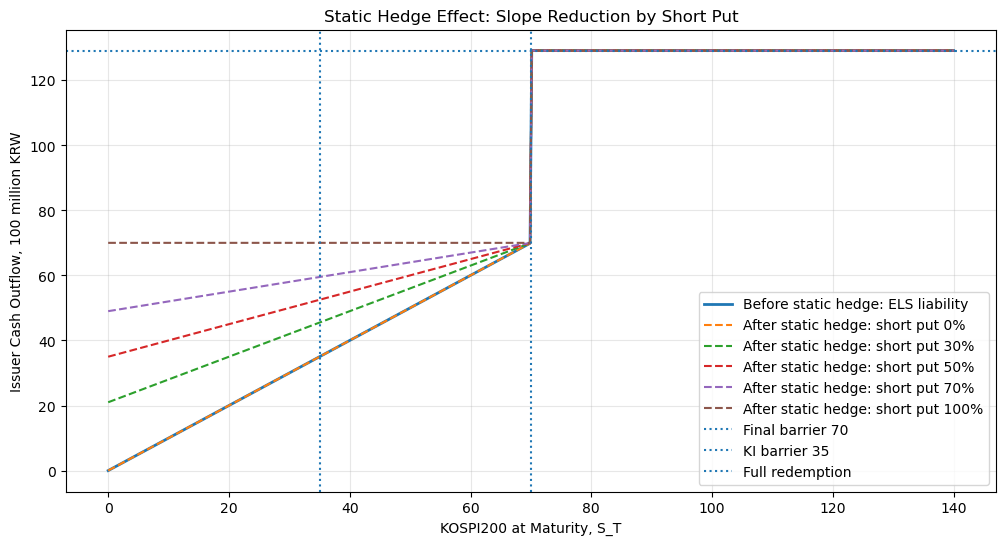

In [7]:
# ============================================================
# 5-X. Visualize Static Hedge Effect on Payoff Slope
# ============================================================

# S_T 구간
S_plot = np.linspace(0, 140, 500)

# 만기 full redemption
full_redemption = NOTIONAL * (1 + els.annual_coupon * els.maturity_years)

# 최종 상환 barrier
final_barrier = els.autocall_barriers[-1] * S0  # 70

# KI 발생 상태에서 ELS 투자자 payoff
# 발행자 입장에서는 지급해야 하는 금액
els_liability_ki = np.where(
    S_plot >= final_barrier,
    full_redemption,
    NOTIONAL * (S_plot / S0)
)

# short put strike
K = PUT_STRIKE

# 100% 정적헤지 기준 수량
# 이 수량이면 S < K 구간에서 ELS liability의 기울기를 거의 상쇄
full_units = FULL_STATIC_UNITS

# 비교할 정적헤지 비율
static_ratios_to_plot = [0.0, 0.3, 0.5, 0.7, 1.0]

plt.figure(figsize=(12, 6))

# 헤지 전 ELS liability
plt.plot(
    S_plot,
    els_liability_ki / 1e8,
    linewidth=2,
    label="Before static hedge: ELS liability"
)

for ratio in static_ratios_to_plot:
    units = full_units * ratio
    
    # short put의 terminal cash outflow
    # put을 매도했으므로 만기에는 max(K-S,0)를 지급해야 함
    short_put_outflow = units * np.maximum(K - S_plot, 0)
    
    # 발행자 관점 정적헤지 후 순지급액
    # premium은 기울기에는 영향이 없으므로 여기서는 제외
    hedged_liability = els_liability_ki + short_put_outflow
    
    plt.plot(
        S_plot,
        hedged_liability / 1e8,
        linestyle="--",
        label=f"After static hedge: short put {ratio:.0%}"
    )

plt.axvline(final_barrier, linestyle=":", label="Final barrier 70")
plt.axvline(els.knock_in_barrier * S0, linestyle=":", label="KI barrier 35")
plt.axhline(full_redemption / 1e8, linestyle=":", label="Full redemption")

plt.title("Static Hedge Effect: Slope Reduction by Short Put")
plt.xlabel("KOSPI200 at Maturity, S_T")
plt.ylabel("Issuer Cash Outflow, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
# ============================================================
# 5-4. Black-Scholes Put Pricing
# ============================================================

def norm_cdf(x):
    """
    Standard normal CDF.
    scipy 없이도 돌아가도록 erf 사용.
    """
    return 0.5 * (1.0 + np.vectorize(erf)(x / np.sqrt(2.0)))


def bs_put_price(S, K, T, r, sigma):
    """
    Black-Scholes European put price.
    
    S, T는 scalar 또는 numpy array 모두 가능.
    """
    S = np.asarray(S, dtype=float)
    T = np.asarray(T, dtype=float)
    
    price = np.zeros_like(S, dtype=float)
    
    intrinsic = np.maximum(K - S, 0.0)
    
    active = T > 1e-10
    
    price[~active] = intrinsic[~active]
    
    if np.any(active):
        S_a = np.maximum(S[active], 1e-10)
        T_a = T[active]
        
        d1 = (
            np.log(S_a / K)
            + (r + 0.5 * sigma ** 2) * T_a
        ) / (
            sigma * np.sqrt(T_a)
        )
        
        d2 = d1 - sigma * np.sqrt(T_a)
        
        price[active] = (
            K * np.exp(-r * T_a) * norm_cdf(-d2)
            - S_a * norm_cdf(-d1)
        )
    
    return price


# scalar 입력용 wrapper
def bs_put_price_scalar(S, K, T, r, sigma):
    return float(bs_put_price(np.array([S]), K, np.array([T]), r, sigma)[0])

In [9]:
# ============================================================
# 5-4-1. Test Put Price
# ============================================================

initial_put_price = bs_put_price_scalar(
    S=S0,
    K=PUT_STRIKE,
    T=PUT_MATURITY,
    r=RISK_FREE_RATE,
    sigma=SIGMA
)

print("Initial put price per unit:", initial_put_price)
print("Initial premium for full static units:", initial_put_price * FULL_STATIC_UNITS)
print("Initial premium, 100 million KRW:", initial_put_price * FULL_STATIC_UNITS / 1e8)

Initial put price per unit: 3.404271310141244
Initial premium for full static units: 340427131.0141244
Initial premium, 100 million KRW: 3.404271310141244


## 수정: 정적헤지 방향 통일

정적헤지는 풋옵션 매도로 통일한다. 이 전략은 ELS 발행자 잔고가 낙인 후 손실구간에서 갖는 음의 기울기를 short put의 양의 손익 기울기로 완화하려는 목적이다. 따라서 여기서의 풋옵션은 발행자 관점의 기울기 상쇄용 매도 포지션이다.


## 수정: 풋옵션 가격 산정 방식 점검

정적헤지에 쓰는 vanilla European put 가격은 현재 가정이 상수변동성 Black-Scholes framework이므로 폐쇄형 Black-Scholes 가격을 기본값으로 쓰는 것이 가장 타당하다. Monte Carlo 가격도 `risk-neutral drift = r`로 기초자산을 시뮬레이션하고 할인된 payoff 평균을 쓰면 이론적으로 타당하다. 다만 vanilla put에는 폐쇄형 해가 있어 Monte Carlo는 계산이 느리고 표본오차가 남으므로, 기본 가격 산정보다는 검산 또는 복잡한 payoff로 확장할 때 쓰는 것이 적절하다.

기존 ELS path를 그대로 가격 산정에 재사용하려면 그 path가 risk-neutral measure에서 생성되었고 만기와 변동성 가정이 동일해야 한다. historical drift path나 실제 성과평가용 P-measure path를 사용하면 공정가격이 아니라 시나리오 기대손익이 된다.


In [10]:
# ============================================================
# 5-4-2. Monte Carlo Put Pricing Cross-check
# 수정: vanilla put 매도 전략의 초기 premium 산정을 BS와 risk-neutral MC로 비교
# ============================================================

def mc_european_put_price(
    S0,
    K,
    T,
    r,
    sigma,
    n_paths=200_000,
    seed=SEED
):
    # Risk-neutral Monte Carlo European put price.
    # Vanilla put에는 Black-Scholes 폐쇄형 가격이 있으므로 MC는 검산 용도로 사용한다.
    rng = np.random.default_rng(seed)
    z = rng.standard_normal(n_paths)
    terminal_price = S0 * np.exp(
        (r - 0.5 * sigma ** 2) * T
        + sigma * np.sqrt(T) * z
    )
    discounted_payoff = np.exp(-r * T) * np.maximum(K - terminal_price, 0.0)
    price = discounted_payoff.mean()
    std_error = discounted_payoff.std(ddof=1) / np.sqrt(n_paths)
    return price, std_error


mc_put_price, mc_put_se = mc_european_put_price(
    S0=S0,
    K=PUT_STRIKE,
    T=PUT_MATURITY,
    r=RISK_FREE_RATE,
    sigma=SIGMA,
    n_paths=200_000,
    seed=SEED
)

put_pricing_comparison = pd.DataFrame([
    {
        "method": "Black-Scholes closed form",
        "put_price": initial_put_price,
        "standard_error": 0.0,
        "ci95_low": initial_put_price,
        "ci95_high": initial_put_price,
        "comment": "Primary method under current constant-volatility BS assumptions",
    },
    {
        "method": "Risk-neutral Monte Carlo",
        "put_price": mc_put_price,
        "standard_error": mc_put_se,
        "ci95_low": mc_put_price - 1.96 * mc_put_se,
        "ci95_high": mc_put_price + 1.96 * mc_put_se,
        "comment": "Valid cross-check if paths are generated under risk-neutral measure",
    },
])

put_pricing_comparison["difference_vs_bs"] = (
    put_pricing_comparison["put_price"] - initial_put_price
)
put_pricing_comparison["difference_vs_bs_pct"] = (
    put_pricing_comparison["difference_vs_bs"] / initial_put_price
)

pricing_comparison_path = OUTPUT_DIR / "static_put_pricing_method_comparison.csv"
put_pricing_comparison.to_csv(
    pricing_comparison_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved put pricing comparison to:", pricing_comparison_path)
display(put_pricing_comparison)


Saved put pricing comparison to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\static_put_pricing_method_comparison.csv


,method,put_price,standard_error,ci95_low,ci95_high,comment,difference_vs_bs,difference_vs_bs_pct
0,Black-Scholes closed form,3.404271,0.000000,3.404271,3.404271,Primary method under current constant-volatili...,0.000000,0.000000
1,Risk-neutral Monte Carlo,3.417402,0.017516,3.383071,3.451734,Valid cross-check if paths are generated under...,0.013131,0.003857


In [11]:
# ============================================================
# 5-5. Principal Growth Factor
# ============================================================

def cash_growth_factor(years, daily_rate=PRINCIPAL_DAILY_RATE):
    """
    years만큼 하루 단위 복리 운용.
    하루 수익률은 0.03 / 365.
    """
    years = np.asarray(years, dtype=float)
    days = np.maximum(np.round(years * 365).astype(int), 0)
    return (1 + daily_rate) ** days


print("1-year growth:", cash_growth_factor(1.0))
print("3-year growth:", cash_growth_factor(3.0))

1-year growth: 1.030453263600551
3-year growth: 1.0941702369885808


# 5-6 path별 put 청산 가격 계산

조기상환된 paht는 조기상환 시점에 put을 청산한다
조기상환이 없는 path는 만기까지 보유하고 만기 payoff를 지급

In [12]:
# ============================================================
# 5-6. Pathwise Static Put Close Value
# ============================================================

n_paths = paths.shape[0]

settlement_index = payoff_df["settlement_index"].astype(int).values
elapsed_years = payoff_df["elapsed_years"].astype(float).values

# 각 path의 ELS settlement 시점 가격
S_settle = paths[np.arange(n_paths), settlement_index]

# put의 잔존만기
tau_remaining = np.maximum(PUT_MATURITY - elapsed_years, 0.0)

# settlement 시점에서 short put을 청산하기 위해 지불해야 하는 가격
put_close_price = bs_put_price(
    S=S_settle,
    K=PUT_STRIKE,
    T=tau_remaining,
    r=RISK_FREE_RATE,
    sigma=SIGMA
)

static_close_df = pd.DataFrame({
    "path_id": np.arange(n_paths),
    "settlement_index": settlement_index,
    "elapsed_years": elapsed_years,
    "S_settle": S_settle,
    "tau_remaining": tau_remaining,
    "put_close_price": put_close_price,
    "payoff_type": payoff_df["payoff_type"].values,
    "autocall_no": payoff_df["autocall_no"].values,
})

display(static_close_df.head())
display(static_close_df.describe())

,path_id,settlement_index,elapsed_years,S_settle,tau_remaining,put_close_price,payoff_type,autocall_no
0,0,128,0.500000,86.483610,2.500000,4.814799,autocall_1,1
1,1,128,0.500000,151.946806,2.500000,0.379648,autocall_1,1
2,2,128,0.500000,112.761641,2.500000,1.710589,autocall_1,1
3,3,128,0.500000,85.336922,2.500000,5.036540,autocall_1,1
4,4,128,0.500000,88.157058,2.500000,4.508259,autocall_1,1


,path_id,settlement_index,elapsed_years,S_settle,tau_remaining,put_close_price,autocall_no
count,"10,000.000000","10,000.000000","10,000.000000","10,000.000000","10,000.000000","10,000.000000","10,000.000000"
mean,"4,999.500000",206.017800,0.799900,102.218051,2.200100,3.495094,1.247000
std,"2,886.895680",186.261134,0.715305,20.889403,0.715305,5.294299,0.966480
min,0.000000,128.000000,0.500000,17.820287,0.000000,0.000000,0.000000
25%,"2,499.750000",128.000000,0.500000,91.414740,2.500000,1.483870,1.000000
50%,"4,999.500000",128.000000,0.500000,101.287378,2.500000,2.423570,1.000000
75%,"7,499.250000",128.000000,0.500000,113.817289,2.500000,3.569990,1.000000
max,"9,999.000000",779.000000,3.000000,242.461523,2.500000,52.179713,6.000000


# 5-7 static hedge 수량 결정 로직

풋옵션 매도는 프리미엄이 들어오지만, 손실 가능성이 있기 때문에 헤지북 제약은 프리미엄이 아니라 위험자본 / margin proxy 기준으로 둔다. 

In [13]:
# ============================================================
# 5-7. Static Hedge Quantity under Hedge Book Constraint
# ============================================================

initial_put_price = bs_put_price_scalar(
    S=S0,
    K=PUT_STRIKE,
    T=PUT_MATURITY,
    r=RISK_FREE_RATE,
    sigma=SIGMA
)

# short put 1단위당 위험자본 proxy
static_margin_per_unit = max(PUT_STRIKE - initial_put_price, 0.0)

print("Initial put premium per unit:", initial_put_price)
print("Static margin proxy per unit:", static_margin_per_unit)
print("Full static units:", FULL_STATIC_UNITS)
print("Full static margin required:", FULL_STATIC_UNITS * static_margin_per_unit)
print("Full static margin required, 100 million KRW:", FULL_STATIC_UNITS * static_margin_per_unit / 1e8)

Initial put premium per unit: 3.404271310141244
Static margin proxy per unit: 66.59572868985876
Full static units: 100000000.0
Full static margin required: 6659572868.985876
Full static margin required, 100 million KRW: 66.59572868985876


# 5-8. Experiment별 static hedge PnL 계산

여기서 experiment_grid의 각 조합별로 static hedge 결과를 계산합니다.

수량은 다음처럼 잡습니다.

target_units = FULL_STATIC_UNITS × static_ratio
max_units_by_budget = static_budget / static_margin_per_unit
actual_units = min(target_units, max_units_by_budget)

정적헤지 비율이 높더라도 헤지북 한도를 넘으면 자동으로 수량이 줄어든다

In [14]:
# ============================================================
# 5-8. Calculate Static Hedge PnL for Each Experiment
# ============================================================

def calculate_static_pnl_for_experiment(
    row,
    initial_put_price,
    put_close_price,
    elapsed_years,
    tau_remaining,
    full_static_units,
    static_margin_per_unit
):
    """
    하나의 experiment 조합에 대해 path별 static hedge terminal PnL 계산.
    """
    
    static_ratio = float(row["static_ratio"])
    static_budget = float(row["static_budget"])
    
    # 목표 수량
    target_units = full_static_units * static_ratio
    
    # 헤지북 제약상 가능한 최대 수량
    if static_margin_per_unit <= 0:
        max_units_by_budget = target_units
    else:
        max_units_by_budget = static_budget / static_margin_per_unit
    
    actual_units = min(target_units, max_units_by_budget)
    
    # 실제 사용 위험자본
    used_static_margin = actual_units * static_margin_per_unit
    
    # 발행 시점에 받은 premium
    initial_premium_cash = actual_units * initial_put_price
    
    # settlement 시점까지 premium을 원금북처럼 운용
    premium_growth_to_settlement = cash_growth_factor(elapsed_years)
    premium_value_at_settlement = initial_premium_cash * premium_growth_to_settlement
    
    # settlement 시점에서 put 청산 비용
    close_cost_at_settlement = actual_units * put_close_price
    
    # settlement 시점 PnL
    static_pnl_at_settlement = premium_value_at_settlement - close_cost_at_settlement
    
    # settlement 이후 만기까지 원금북처럼 운용
    growth_to_maturity = cash_growth_factor(tau_remaining)
    static_terminal_pnl = static_pnl_at_settlement * growth_to_maturity
    
    metadata = {
        "target_units": target_units,
        "actual_units": actual_units,
        "max_units_by_budget": max_units_by_budget,
        "used_static_margin": used_static_margin,
        "unused_static_budget": static_budget - used_static_margin,
        "initial_premium_cash": initial_premium_cash,
        "is_budget_binding": actual_units < target_units - 1e-8,
    }
    
    return static_pnl_at_settlement, static_terminal_pnl, metadata

In [15]:
# ============================================================
# 5-8-1. Run Static Hedge PnL Calculation
# ============================================================

experiment_grid = experiment_grid.copy()
experiment_grid["experiment_id"] = np.arange(len(experiment_grid))

n_experiments = len(experiment_grid)

static_pnl_settlement_matrix = np.zeros((n_experiments, n_paths))
static_pnl_terminal_matrix = np.zeros((n_experiments, n_paths))

static_metadata_list = []

for i, row in experiment_grid.iterrows():
    pnl_settle, pnl_terminal, metadata = calculate_static_pnl_for_experiment(
        row=row,
        initial_put_price=initial_put_price,
        put_close_price=put_close_price,
        elapsed_years=elapsed_years,
        tau_remaining=tau_remaining,
        full_static_units=FULL_STATIC_UNITS,
        static_margin_per_unit=static_margin_per_unit
    )
    
    static_pnl_settlement_matrix[i, :] = pnl_settle
    static_pnl_terminal_matrix[i, :] = pnl_terminal
    
    static_metadata = {
        "experiment_id": int(row["experiment_id"]),
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        "static_budget": row["static_budget"],
        "dynamic_budget": row["dynamic_budget"],
        "put_strike": PUT_STRIKE,
        "initial_put_price": initial_put_price,
        "static_margin_per_unit": static_margin_per_unit,
        **metadata
    }
    
    static_metadata_list.append(static_metadata)

static_metadata_df = pd.DataFrame(static_metadata_list)

print("static_pnl_settlement_matrix shape:", static_pnl_settlement_matrix.shape)
print("static_pnl_terminal_matrix shape:", static_pnl_terminal_matrix.shape)

display(static_metadata_df.head(15))

static_pnl_settlement_matrix shape: (33, 10000)
static_pnl_terminal_matrix shape: (33, 10000)


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,static_budget,dynamic_budget,put_strike,initial_put_price,static_margin_per_unit,target_units,actual_units,max_units_by_budget,used_static_margin,unused_static_budget,initial_premium_cash,is_budget_binding
0,0,0.300000,0.700000,0.000000,1.000000,0.000000,"7,000,000,000.000000",70.000000,3.404271,66.595729,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,False
1,1,0.300000,0.700000,0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000",70.000000,3.404271,66.595729,"10,000,000.000000","10,000,000.000000","10,511,184.632575","665,957,286.898588","34,042,713.101412","34,042,713.101412",False
2,2,0.300000,0.700000,0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000",70.000000,3.404271,66.595729,"20,000,000.000000","20,000,000.000000","21,022,369.265151","1,331,914,573.797175","68,085,426.202825","68,085,426.202825",False
3,3,0.300000,0.700000,0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000",70.000000,3.404271,66.595729,"30,000,000.000000","30,000,000.000000","31,533,553.897726","1,997,871,860.695763","102,128,139.304237","102,128,139.304237",False
4,4,0.300000,0.700000,0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000",70.000000,3.404271,66.595729,"40,000,000.000000","40,000,000.000000","42,044,738.530301","2,663,829,147.594350","136,170,852.405650","136,170,852.405650",False
5,5,0.300000,0.700000,0.500000,0.500000,"3,500,000,000.000000","3,500,000,000.000000",70.000000,3.404271,66.595729,"50,000,000.000000","50,000,000.000000","52,555,923.162877","3,329,786,434.492938","170,213,565.507062","170,213,565.507062",False
6,6,0.300000,0.700000,0.600000,0.400000,"4,200,000,000.000001","2,800,000,000.000000",70.000000,3.404271,66.595729,"60,000,000.000000","60,000,000.000000","63,067,107.795452","3,995,743,721.391526","204,256,278.608475","204,256,278.608475",False
7,7,0.300000,0.700000,0.700000,0.300000,"4,900,000,000.000000","2,100,000,000.000000",70.000000,3.404271,66.595729,"70,000,000.000000","70,000,000.000000","73,578,292.428027","4,661,701,008.290113","238,298,991.709887","238,298,991.709887",False
8,8,0.300000,0.700000,0.800000,0.200000,"5,600,000,000.000000","1,400,000,000.000000",70.000000,3.404271,66.595729,"80,000,000.000000","80,000,000.000000","84,089,477.060603","5,327,658,295.188701","272,341,704.811299","272,341,704.811300",False
9,9,0.300000,0.700000,0.900000,0.100000,"6,300,000,000.000000","700,000,000.000000",70.000000,3.404271,66.595729,"90,000,000.000000","90,000,000.000000","94,600,661.693178","5,993,615,582.087288","306,384,417.912712","306,384,417.912712",False


In [16]:
# ============================================================
# 5-9. Static Hedge Performance Summary
# ============================================================

static_perf_summary = []

for i, row in static_metadata_df.iterrows():
    pnl = static_pnl_terminal_matrix[i, :]
    
    static_perf_summary.append({
        "experiment_id": row["experiment_id"],
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        "actual_units": row["actual_units"],
        "used_static_margin": row["used_static_margin"],
        "unused_static_budget": row["unused_static_budget"],
        "is_budget_binding": row["is_budget_binding"],
        "mean_static_terminal_pnl": np.mean(pnl),
        "std_static_terminal_pnl": np.std(pnl, ddof=1),
        "min_static_terminal_pnl": np.min(pnl),
        "max_static_terminal_pnl": np.max(pnl),
        "p05_static_terminal_pnl": np.percentile(pnl, 5),
        "p50_static_terminal_pnl": np.percentile(pnl, 50),
        "p95_static_terminal_pnl": np.percentile(pnl, 95),
    })

static_perf_summary = pd.DataFrame(static_perf_summary)

display(static_perf_summary.head(15))

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,actual_units,used_static_margin,unused_static_budget,is_budget_binding,mean_static_terminal_pnl,std_static_terminal_pnl,min_static_terminal_pnl,max_static_terminal_pnl,p05_static_terminal_pnl,p50_static_terminal_pnl,p95_static_terminal_pnl
0,0,0.300000,0.700000,0.000000,1.000000,0.000000,0.000000,0.000000,False,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,0.300000,0.700000,0.100000,0.900000,"10,000,000.000000","665,957,286.898588","34,042,713.101412",False,"603,412.788824","52,822,126.925169","-484,548,605.321341","37,248,523.461907","-42,415,899.074476","11,346,143.673050","31,617,657.642174"
2,2,0.300000,0.700000,0.200000,0.800000,"20,000,000.000000","1,331,914,573.797175","68,085,426.202825",False,"1,206,825.577647","105,644,253.850337","-969,097,210.642683","74,497,046.923813","-84,831,798.148953","22,692,287.346101","63,235,315.284348"
3,3,0.300000,0.700000,0.300000,0.700000,"30,000,000.000000","1,997,871,860.695763","102,128,139.304237",False,"1,810,238.366471","158,466,380.775506","-1,453,645,815.964024","111,745,570.385720","-127,247,697.223429","34,038,431.019151","94,852,972.926523"
4,4,0.300000,0.700000,0.400000,0.600000,"40,000,000.000000","2,663,829,147.594350","136,170,852.405650",False,"2,413,651.155294","211,288,507.700674","-1,938,194,421.285365","148,994,093.847627","-169,663,596.297906","45,384,574.692202","126,470,630.568697"
5,5,0.300000,0.700000,0.500000,0.500000,"50,000,000.000000","3,329,786,434.492938","170,213,565.507062",False,"3,017,063.944118","264,110,634.625843","-2,422,743,026.606707","186,242,617.309534","-212,079,495.372382","56,730,718.365252","158,088,288.210871"
6,6,0.300000,0.700000,0.600000,0.400000,"60,000,000.000000","3,995,743,721.391526","204,256,278.608475",False,"3,620,476.732942","316,932,761.551012","-2,907,291,631.928048","223,491,140.771440","-254,495,394.446858","68,076,862.038302","189,705,945.853045"
7,7,0.300000,0.700000,0.700000,0.300000,"70,000,000.000000","4,661,701,008.290113","238,298,991.709887",False,"4,223,889.521765","369,754,888.476180","-3,391,840,237.249389","260,739,664.233347","-296,911,293.521335","79,423,005.711353","221,323,603.495219"
8,8,0.300000,0.700000,0.800000,0.200000,"80,000,000.000000","5,327,658,295.188701","272,341,704.811299",False,"4,827,302.310589","422,577,015.401349","-3,876,388,842.570730","297,988,187.695254","-339,327,192.595811","90,769,149.384403","252,941,261.137394"
9,9,0.300000,0.700000,0.900000,0.100000,"90,000,000.000000","5,993,615,582.087288","306,384,417.912712",False,"5,430,715.099412","475,399,142.326517","-4,360,937,447.892071","335,236,711.157160","-381,743,091.670287","102,115,293.057454","284,558,918.779568"


In [17]:
# ============================================================
# 5-10. Static Performance by Static Ratio
# ============================================================

static_ratio_summary = (
    static_perf_summary
    .groupby("static_ratio")
    .agg(
        avg_mean_pnl=("mean_static_terminal_pnl", "mean"),
        avg_std_pnl=("std_static_terminal_pnl", "mean"),
        avg_p05_pnl=("p05_static_terminal_pnl", "mean"),
        avg_used_margin=("used_static_margin", "mean"),
        budget_binding_count=("is_budget_binding", "sum")
    )
    .reset_index()
)

static_ratio_summary

,static_ratio,avg_mean_pnl,avg_std_pnl,avg_p05_pnl,avg_used_margin,budget_binding_count
0,0.000000,0.000000,0.000000,0.000000,0.000000,0
1,0.100000,"442,759.814674","38,758,732.929181","-31,123,065.273530","488,652,428.966196",2
2,0.200000,"885,519.629348","77,517,465.858362","-62,246,130.547061","977,304,857.932392",2
3,0.300000,"1,328,279.444022","116,276,198.787543","-93,369,195.820591","1,465,957,286.898588",2
4,0.400000,"1,771,039.258695","155,034,931.716724","-124,492,261.094121","1,954,609,715.864784",2
5,0.500000,"2,213,799.073369","193,793,664.645905","-155,615,326.367652","2,443,262,144.830979",2
6,0.600000,"2,656,558.888043","232,552,397.575086","-186,738,391.641182","2,931,914,573.797176",2
7,0.700000,"3,099,318.702717","271,311,130.504267","-217,861,456.914712","3,420,567,002.763372",2
8,0.800000,"3,542,078.517391","310,069,863.433448","-248,984,522.188243","3,909,219,431.729567",2
9,0.900000,"3,984,838.332065","348,828,596.362629","-280,107,587.461773","4,397,871,860.695763",2


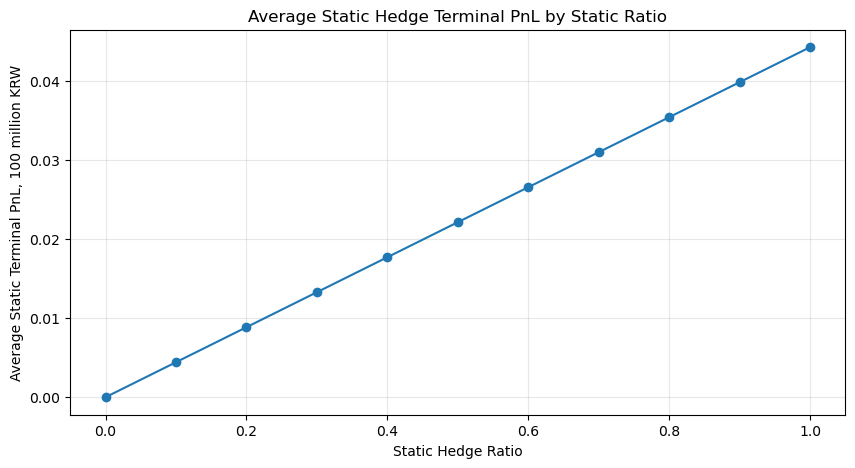

In [18]:
# ============================================================
# 5-10-1. Plot Static Hedge Mean PnL by Static Ratio
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    static_ratio_summary["static_ratio"],
    static_ratio_summary["avg_mean_pnl"] / 1e8,
    marker="o"
)
plt.title("Average Static Hedge Terminal PnL by Static Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("Average Static Terminal PnL, 100 million KRW")
plt.grid(True, alpha=0.3)
plt.show()

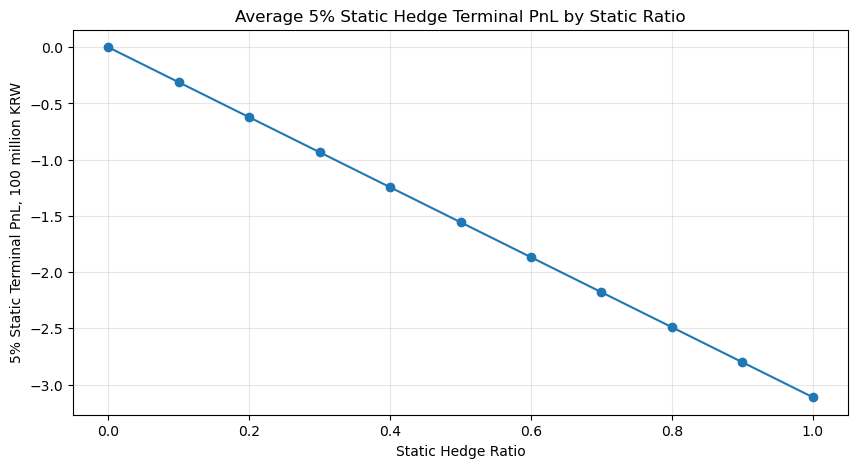

In [19]:
# ============================================================
# 5-10-2. Plot Static Hedge 5% PnL by Static Ratio
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    static_ratio_summary["static_ratio"],
    static_ratio_summary["avg_p05_pnl"] / 1e8,
    marker="o"
)
plt.title("Average 5% Static Hedge Terminal PnL by Static Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("5% Static Terminal PnL, 100 million KRW")
plt.grid(True, alpha=0.3)
plt.show()

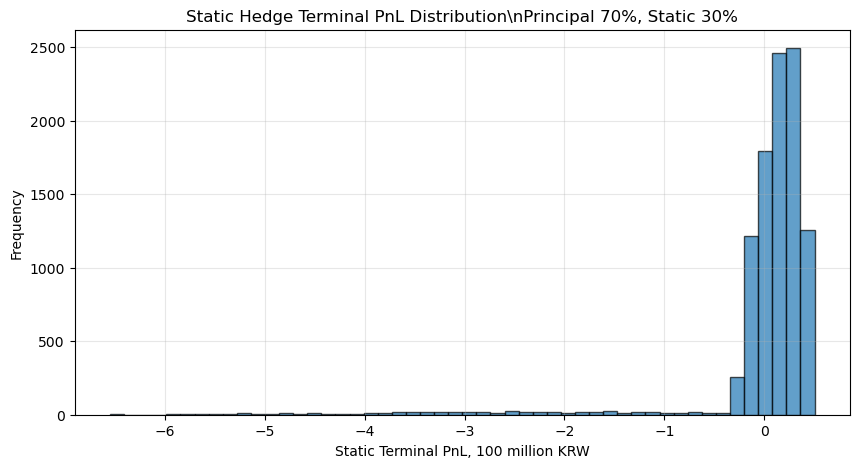

Experiment ID: 25


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,static_budget,dynamic_budget,put_strike,initial_put_price,static_margin_per_unit,target_units,actual_units,max_units_by_budget,used_static_margin,unused_static_budget,initial_premium_cash,is_budget_binding
25,25,0.700000,0.300000,0.300000,0.700000,"900,000,000.000000","2,100,000,000.000000",70.000000,3.404271,66.595729,"30,000,000.000000","13,514,380.241883","13,514,380.241883","900,000,000.000000",0.000000,"46,006,616.931781",True


Mean PnL: 815474.9870976927
5% PnL: -57322458.83937892
Min PnL: -654837409.7986495


In [20]:
# ============================================================
# 5-11. Example Static Hedge PnL Distribution
# ============================================================

example_row = static_metadata_df[
    (static_metadata_df["principal_book_ratio"] == 0.70)
    & (np.isclose(static_metadata_df["static_ratio"], 0.30))
]

if len(example_row) > 0:
    example_id = int(example_row.iloc[0]["experiment_id"])
    
    example_pnl = static_pnl_terminal_matrix[example_id, :]
    
    plt.figure(figsize=(10, 5))
    plt.hist(example_pnl / 1e8, bins=50, edgecolor="black", alpha=0.7)
    plt.title("Static Hedge Terminal PnL Distribution\\nPrincipal 70%, Static 30%")
    plt.xlabel("Static Terminal PnL, 100 million KRW")
    plt.ylabel("Frequency")
    plt.grid(True, alpha=0.3)
    plt.show()
    
    print("Experiment ID:", example_id)
    display(example_row)
    print("Mean PnL:", example_pnl.mean())
    print("5% PnL:", np.percentile(example_pnl, 5))
    print("Min PnL:", example_pnl.min())

In [21]:
# ============================================================
# 5-12. Save Section 5 Outputs
# ============================================================

np.save(
    OUTPUT_DIR / "static_pnl_settlement_matrix.npy",
    static_pnl_settlement_matrix
)

np.save(
    OUTPUT_DIR / "static_pnl_terminal_matrix.npy",
    static_pnl_terminal_matrix
)

static_metadata_path = OUTPUT_DIR / "static_hedge_metadata.csv"
static_perf_summary_path = OUTPUT_DIR / "static_hedge_performance_summary.csv"
static_ratio_summary_path = OUTPUT_DIR / "static_hedge_ratio_summary.csv"
static_close_path = OUTPUT_DIR / "static_put_close_by_path.csv"

static_metadata_df.to_csv(
    static_metadata_path,
    index=False,
    encoding="utf-8-sig"
)

static_perf_summary.to_csv(
    static_perf_summary_path,
    index=False,
    encoding="utf-8-sig"
)

static_ratio_summary.to_csv(
    static_ratio_summary_path,
    index=False,
    encoding="utf-8-sig"
)

static_close_df.to_csv(
    static_close_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved static PnL settlement matrix")
print("Saved static PnL terminal matrix")
print("Saved static metadata to:", static_metadata_path)
print("Saved static performance summary to:", static_perf_summary_path)
print("Saved static ratio summary to:", static_ratio_summary_path)
print("Saved static close info to:", static_close_path)

Saved static PnL settlement matrix
Saved static PnL terminal matrix
Saved static metadata to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\static_hedge_metadata.csv
Saved static performance summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\static_hedge_performance_summary.csv
Saved static ratio summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\static_hedge_ratio_summary.csv
Saved static close info to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\static_put_close_by_path.csv


## 수정: 정적헤지 해석

본 프로젝트에서 정적헤지는 ELS 발행자가 보유한 내재적인 long-put-like exposure의 기울기를 상쇄하기 위한 vanilla put 매도 전략으로 설정한다. 따라서 section 5의 premium, margin proxy, 청산비용, terminal PnL은 모두 short put 기준으로 해석한다.
